# 04. Seller reliability score and business impact

**Purpose:** Score the sellers that have enough volume, tier them, test how sensitive the ranking is to the weights, cross-check the repeat-purchase result from SQL query 11, and size the impact with labelled assumptions.

**Inputs:** views `vw_seller_scorecard` and `vw_order_base`.

**Outputs:** `docs/figures/seller_tiers_scatter.png`; table `seller_scores` in MySQL; `powerbi/seller_scores.csv`.

**Run order:** after notebook 03. Notebook 05 needs the `seller_scores` table created here.

## 1. Setup

In [1]:
import os
from pathlib import Path
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.types import VARCHAR

ROOT = Path.cwd().parent
load_dotenv(ROOT / ".env")
engine = create_engine(
    f"mysql+pymysql://{os.getenv('DB_USER')}:{quote_plus(os.getenv('DB_PASSWORD'))}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}?charset=utf8mb4"
)
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def run(sql):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

sns.set_theme(style="whitegrid")

## 2. Load the qualifying sellers

Only sellers with at least 30 delivered orders are scored. With fewer orders a late rate is mostly luck.

In [2]:
sc = run("SELECT * FROM vw_seller_scorecard WHERE meets_min_orders = 1")
num = ["orders", "revenue", "late_rate_pct", "avg_handling_days", "avg_review", "pct_1_2_star"]
sc[num] = sc[num].apply(pd.to_numeric, errors="coerce")
assert len(sc) == 626, "expected 626 sellers with 30+ orders"
print(len(sc), "qualifying sellers")
print(sc[num].isna().sum())
display(sc[num].describe().round(2))

total_rev = float(run("SELECT SUM(revenue) AS r FROM vw_seller_scorecard").iloc[0, 0])
print(f"Qualifying sellers cover {100 * sc['revenue'].sum() / total_rev:.1f}% of delivered-order revenue")

626 qualifying sellers
orders               0
revenue              0
late_rate_pct        0
avg_handling_days    0
avg_review           0
pct_1_2_star         0
dtype: int64


,orders,revenue,late_rate_pct,avg_handling_days,avg_review,pct_1_2_star
count,626.00,626.00,626.00,626.00,626.00,626.00
mean,130.13,16262.13,6.53,3.21,4.16,12.96
std,201.14,26871.32,4.90,2.03,0.30,7.20
min,30.00,345.60,0.00,0.94,2.39,0.00
25%,43.00,4225.61,3.14,1.96,4.00,8.18
50%,68.00,7811.69,5.48,2.58,4.19,11.86
75%,127.75,15200.13,9.09,3.79,4.36,16.25
max,1815.00,226987.93,32.56,18.12,5.00,59.81


Qualifying sellers cover 77.1% of delivered-order revenue


## 3. Build the score

Score = 50% on-time rate + 30% handling speed + 20% average review. Each input is rescaled to 0-1 after capping at the 5th and 95th percentile so one extreme seller cannot squash the rest.

- **On-time (50%)** is the promise the whole project is about.
- **Handling speed (30%)** is the part of delay the seller controls; carrier transit is not their fault.
- **Review (20%)** is useful but noisy, and lateness already drives it, so a larger weight would count lateness twice.

In [3]:
def scale_0_1(s, higher_is_better=True):
    """Rescale to 0-1 after capping extremes at the 5th and 95th percentile."""
    lo, hi = s.quantile(0.05), s.quantile(0.95)
    scaled = (s.clip(lo, hi) - lo) / (hi - lo)
    return scaled if higher_is_better else 1 - scaled

sc["ontime_s"] = scale_0_1(100 - sc["late_rate_pct"])
sc["speed_s"]  = scale_0_1(sc["avg_handling_days"], higher_is_better=False)   # fewer days = better
sc["review_s"] = scale_0_1(sc["avg_review"])

def reliability_score(w):
    return 100 * (w[0] * sc["ontime_s"] + w[1] * sc["speed_s"] + w[2] * sc["review_s"])

W_BASE = (0.50, 0.30, 0.20)     # on-time, handling speed, review
sc["score"] = reliability_score(W_BASE)

cols = ["seller_id", "seller_state", "orders", "revenue", "late_rate_pct", "avg_handling_days", "avg_review", "score"]
display(sc.sort_values("score", ascending=False).head(10)[cols].round(2))
display(sc.sort_values("score").head(10)[cols].round(2))

,seller_id,seller_state,orders,revenue,late_rate_pct,avg_handling_days,avg_review,score
520,d566c37fa119d5e66c4e9052e83ee4ea,SP,64,5109.80,0.0,1.42,4.68,100.00
443,b410bdd36d5db7a65dcd42b7ead933b8,GO,42,7368.90,0.0,1.48,4.81,100.00
272,6df688df543f90e9b38f4319e75a9d88,MG,39,1891.76,0.0,1.54,4.56,99.51
560,e49c26c3edfa46d227d5121a6b6e4d37,PE,34,3624.35,0.0,1.74,4.56,98.41
423,acce39e832338debb07b02385cde5967,MG,44,4748.10,0.0,1.27,4.48,98.08
291,718539d38d07dd351c76db862760e2e2,SP,35,1273.01,0.0,1.94,4.63,97.53
253,65febd49fd28ec955651299159b1f527,SP,33,4136.71,0.0,1.03,4.45,97.44
355,8ae520247981aa06bc94abddf5f46d34,SC,62,15907.11,0.0,1.42,4.44,97.23
130,31561f325664a8a7aba4c8d0c3a9b3db,SP,35,2572.29,0.0,2.00,4.69,97.20
219,57e632711dec9ec14ca7546769483e7e,SC,62,6350.06,0.0,1.61,4.42,96.14


,seller_id,seller_state,orders,revenue,late_rate_pct,avg_handling_days,avg_review,score
426,ad781527c93d00d89a11eecd9dcad7c1,SP,38,6039.63,31.58,11.59,3.34,0.00
337,835f0f7810c76831d6c7d24c7a646d4d,SP,42,4990.20,26.19,9.61,3.36,0.00
349,88460e8ebdecbfecb5f9601833981930,PR,244,31131.60,17.21,7.88,3.42,0.00
409,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,96,8646.90,21.88,7.23,3.03,0.00
213,54965bbe3e4f07ae045b90b0b8541f52,PR,73,10351.70,30.14,15.31,3.14,0.00
287,712e6ed8aa4aa1fa65dab41fed5737e4,SC,77,39385.00,20.78,8.05,3.39,0.00
476,c60b801f2d52c7f7f91de00870882a75,SP,39,11296.50,15.38,7.31,3.44,0.89
491,cac4c8e7b1ca6252d8f20b2fc1a2e4af,SP,74,4128.19,17.57,6.14,3.56,4.49
241,6039e27294dc75811c0d8a39069f52c0,SP,63,13500.80,17.46,6.51,3.73,4.54
466,beadbee30901a7f61d031b6b686095ad,SP,64,4373.98,23.44,7.50,3.91,5.92


## 4. Tiers and sensitivity check

Bottom 15% by score = *At risk*, next 25% = *Watch*, top 60% = *Reliable* (a judgement call). The table shows how much the top 20 and the tiers change under five other weightings.

In [4]:
def assign_tier(score_series):
    pct = score_series.rank(pct=True)
    return pd.cut(pct, bins=[0, 0.15, 0.40, 1.0],
                  labels=["At risk", "Watch", "Reliable"], include_lowest=True)

def top_n(score_series, n=20):
    tmp = sc.assign(s=score_series).sort_values(["s", "orders"], ascending=False)
    return set(tmp["seller_id"].head(n))

sc["tier"] = assign_tier(sc["score"])
base_top20 = top_n(sc["score"])
base_tier = sc["tier"]

weight_sets = {
    "base 50/30/20":          (0.50, 0.30, 0.20),
    "equal 33/33/33":         (1/3, 1/3, 1/3),
    "on-time heavy 70/20/10": (0.70, 0.20, 0.10),
    "speed heavy 30/50/20":   (0.30, 0.50, 0.20),
    "review heavy 30/20/50":  (0.30, 0.20, 0.50),
    "no review 60/40/0":      (0.60, 0.40, 0.00),
}
rows = []
for name, w in weight_sets.items():
    alt = reliability_score(w)
    rho, _ = stats.spearmanr(sc["score"], alt)
    rows.append({"weights (on-time/speed/review)": name,
                 "top20_overlap_with_base": len(base_top20 & top_n(alt)),
                 "rank_correlation": round(rho, 3),
                 "pct_sellers_same_tier": round(100 * (assign_tier(alt) == base_tier).mean(), 1)})
display(pd.DataFrame(rows))

,weights (on-time/speed/review),top20_overlap_with_base,rank_correlation,pct_sellers_same_tier
0,base 50/30/20,20,1.000,100.0
1,equal 33/33/33,14,0.976,92.0
2,on-time heavy 70/20/10,17,0.974,86.6
3,speed heavy 30/50/20,16,0.960,86.9
4,review heavy 30/20/50,11,0.938,85.0
5,no review 60/40/0,18,0.971,91.4


## 5. Tier profile

,sellers,orders,revenue,median_late_pct,median_handling_days,mean_seller_review,pct_of_scored_revenue
tier,,,,,,,
Reliable,376,47365,6096805.18,3.66,2.14,4.29,59.9
Watch,157,25466,2893857.01,8.70,3.35,4.06,28.4
At risk,93,8628,1189433.20,13.89,5.16,3.77,11.7


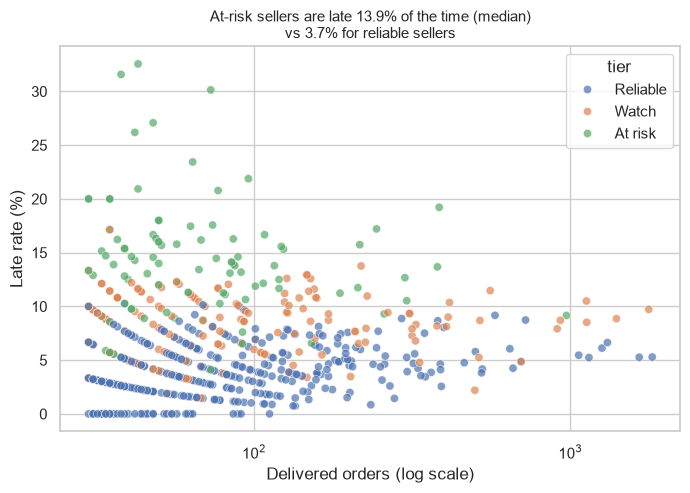

In [5]:
tier_tbl = (sc.groupby("tier", observed=True)
              .agg(sellers=("seller_id", "count"), orders=("orders", "sum"), revenue=("revenue", "sum"),
                   median_late_pct=("late_rate_pct", "median"),
                   median_handling_days=("avg_handling_days", "median"),
                   mean_seller_review=("avg_review", "mean"))
              .round(2))
tier_tbl["pct_of_scored_revenue"] = (100 * tier_tbl["revenue"] / tier_tbl["revenue"].sum()).round(1)
display(tier_tbl.loc[["Reliable", "Watch", "At risk"]])

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=sc, x="orders", y="late_rate_pct", hue="tier",
                hue_order=["Reliable", "Watch", "At risk"], alpha=0.7, ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Delivered orders (log scale)")
ax.set_ylabel("Late rate (%)")
ax.set_title("At-risk sellers are late 13.9% of the time (median)\nvs 3.7% for reliable sellers", fontsize=11)
fig.savefig(FIG / "seller_tiers_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Repeat purchase by first-order lateness (pandas cross-check of SQL query 11)

Repeat rate uses `customer_unique_id`. Only first orders placed before March 2018 are used so every customer had at least about six months to come back.

In [6]:
cust = run("""
    SELECT customer_unique_id, order_id, purchase_ts, is_valid_delivery, is_late, delay_days, items_revenue
    FROM vw_order_base
    WHERE order_status NOT IN ('canceled', 'unavailable')
""")
cnum = ["is_valid_delivery", "is_late", "delay_days", "items_revenue"]
cust[cnum] = cust[cnum].apply(pd.to_numeric, errors="coerce")
cust["purchase_ts"] = pd.to_datetime(cust["purchase_ts"])
cust = cust.sort_values(["customer_unique_id", "purchase_ts", "order_id"])
cust["total_orders"] = cust.groupby("customer_unique_id")["order_id"].transform("size")

first = cust.groupby("customer_unique_id").head(1)
first = first[(first["is_valid_delivery"] == 1) & (first["purchase_ts"] < "2018-03-01")].copy()
first["repeat"] = (first["total_orders"] >= 2).astype(int)
first["group"] = np.select([first["is_late"] == 0, first["delay_days"] <= 7],
                           ["1. on time", "2. 1-7 days late"], default="3. 8+ days late")

repeat_tbl = (first.groupby("group")
                   .agg(customers=("repeat", "size"), repeat_customers=("repeat", "sum"),
                        repeat_rate_pct=("repeat", lambda s: round(100 * s.mean(), 2))))
display(repeat_tbl)      # cross-check: matches SQL query 11, part B

first["late_any"] = (first["is_late"] == 1).astype(int)
table = pd.crosstab(first["late_any"], first["repeat"])
chi2, p_chi, _, _ = stats.chi2_contingency(table)
rate_on   = first.loc[first["late_any"] == 0, "repeat"].mean()
rate_late = first.loc[first["late_any"] == 1, "repeat"].mean()
print(f"Repeat rate: on time {100*rate_on:.2f}% vs late {100*rate_late:.2f}%  "
      f"(gap {100*(rate_on-rate_late):+.2f} pp, chi-square p = {p_chi:.3g})")

,customers,repeat_customers,repeat_rate_pct
group,,,
1. on time,51800,2120,4.09
2. 1-7 days late,1955,61,3.12
3. 8+ days late,1714,51,2.98


Repeat rate: on time 4.09% vs late 3.05%  (gap +1.04 pp, chi-square p = 0.00225)


## 7. Impact, with labelled assumptions

The scenarios are illustrations, not forecasts: they assume a share of the repeat-rate gap is caused by lateness, one repeat order per recovered customer, and the average order value.

In [7]:
aov = cust["items_revenue"].mean()
n_late = int(first["late_any"].sum())
gap = rate_on - rate_late
print(f"Assumptions: average order value = BRL {aov:,.0f}; one repeat order per recovered customer; "
      f"{n_late:,} customers had a late first delivery (before Mar 2018)")

if gap > 0:
    for share in [0.25, 0.50, 1.00]:
        lost = n_late * gap * share
        print(f"If {share:.0%} of the gap is caused by lateness: ~{lost:,.0f} fewer repeat customers, ~BRL {lost*aov:,.0f} revenue")
else:
    print("No repeat-rate gap in this data, so no revenue impact is claimed.")

# Where are the excess late orders?
st = run("SELECT customer_state, COUNT(*) AS orders, SUM(is_late) AS late_orders FROM vw_order_base WHERE is_valid_delivery = 1 GROUP BY customer_state")
st[["orders", "late_orders"]] = st[["orders", "late_orders"]].astype(float)
national = st["late_orders"].sum() / st["orders"].sum()
st["excess_late"] = (st["late_orders"] - national * st["orders"]).clip(lower=0)
print(f"\nNational late rate: {100*national:.2f}%")
print(f"Late orders above the national rate, all states: {st['excess_late'].sum():,.0f} "
      f"({100*st['excess_late'].sum()/st['late_orders'].sum():.1f}% of all late orders)")
display(st.sort_values("excess_late", ascending=False).head(6).round(0))

Assumptions: average order value = BRL 137; one repeat order per recovered customer; 3,669 customers had a late first delivery (before Mar 2018)
If 25% of the gap is caused by lateness: ~10 fewer repeat customers, ~BRL 1,311 revenue
If 50% of the gap is caused by lateness: ~19 fewer repeat customers, ~BRL 2,622 revenue
If 100% of the gap is caused by lateness: ~38 fewer repeat customers, ~BRL 5,244 revenue

National late rate: 6.78%
Late orders above the national rate, all states: 1,399 (21.4% of all late orders)


,customer_state,orders,late_orders,excess_late
0,RJ,12330.0,1495.0,659.0
5,BA,3252.0,395.0,174.0
8,CE,1278.0,176.0,89.0
13,ES,1989.0,214.0,79.0
14,MA,714.0,125.0,77.0
6,AL,397.0,85.0,58.0


## 8. Save the scores for SQL and Power BI

In [8]:
out = sc[["seller_id", "seller_state", "orders", "late_rate_pct", "avg_handling_days", "avg_review",
          "score", "tier"]].copy()
out["tier"] = out["tier"].astype(str)
out["score"] = out["score"].round(2)
out.to_sql("seller_scores", engine, if_exists="replace", index=False,
           dtype={"seller_id": VARCHAR(32), "seller_state": VARCHAR(2), "tier": VARCHAR(10)})
out.to_csv(ROOT / "powerbi" / "seller_scores.csv", index=False)
print(run("SELECT tier, COUNT(*) AS sellers FROM seller_scores GROUP BY tier"))

       tier  sellers
0  Reliable      376
1   At risk       93
2     Watch      157


## Findings

- 626 sellers have 30+ orders (21% of the 2,965 sellers with a delivered order) and cover 77.1% of delivered-order revenue.
- **Sensitivity:** rank correlation with five alternative weightings is 0.94-0.98 and 85-92% of sellers keep their tier, but the exact top-20 overlap ranges from 11 to 18. Use tiers, not exact ranks.
- **Tiers:** Reliable 376, Watch 157, At risk 93. At-risk sellers are late 13.9% of the time (median) vs 3.7% for Reliable, and take about 5.2 days to hand over to the carrier vs 2.1. They hold 11.7% of scored revenue.
- **Repeat purchase:** 4.09% when the first order was on time, 3.12% when 1-7 days late, 2.98% when 8+ days late (on time vs late: 4.09% vs 3.05%, chi-square p = 0.002). The gap is about 1 percentage point.
- **Impact:** 3,669 customers had a late first delivery. If 25-100% of the gap is caused by lateness, that is roughly 10-38 customers and BRL 1.3K-5.2K. The direct repeat-purchase loss is small; the review damage is the larger cost.
- Matching every above-average state to the national rate would remove only 21.4% of late orders (RJ 659, BA 174, CE 89), so lateness is broad-based.